<a href="https://colab.research.google.com/github/muneer-ahmad10/mini-gpt-pytorch/blob/main/Mini_GPT_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Mini GPT from Scratch (PyTorch)

A small decoder-only transformer (GPT-style) trained on character-level text (Tiny Shakespeare).

**Components built by hand:** token + positional embeddings, causal multi-head self-attention, residual connections, LayerNorm, feed-forward blocks, next-token training loop, and autoregressive text generation.

**Colab setup:** Runtime -> Change runtime type -> **T4 GPU**, then run all cells.

In [ ]:
import math
import time
import torch
import torch.nn as nn
from torch.nn import functional as F
import matplotlib.pyplot as plt

torch.manual_seed(1337)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Using device:', device)

Using device: cuda


## 1. Load the data

In [ ]:
!wget -q -O input.txt https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt

with open('input.txt', 'r', encoding='utf-8') as f:
    text = f.read()

print('Characters in dataset:', len(text))
print(text[:300])

Characters in dataset: 1115394
First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.

All:
We know't, we know't.

First Citizen:
Let us


## 2. Character-level tokenizer and train/validation split

In [ ]:
chars = sorted(list(set(text)))
vocab_size = len(chars)
print('Vocabulary size:', vocab_size)

stoi = {ch: i for i, ch in enumerate(chars)}
itos = {i: ch for i, ch in enumerate(chars)}

def encode(s):
    return [stoi[c] for c in s]

def decode(ids):
    return ''.join(itos[i] for i in ids)

data = torch.tensor(encode(text), dtype=torch.long)
n = int(0.9 * len(data))
train_data, val_data = data[:n], data[n:]
print('Train tokens:', len(train_data), '| Validation tokens:', len(val_data))

Vocabulary size: 65
Train tokens: 1003854 | Validation tokens: 111540


## 3. Hyperparameters and batching

In [ ]:
# Model
batch_size = 64        # sequences per batch
block_size = 128       # context length (max tokens the model sees)
n_embd = 256           # embedding dimension
n_head = 4             # attention heads
n_layer = 4            # transformer blocks
dropout = 0.2
learning_rate = 3e-4
max_iters = 3000
eval_interval = 250
eval_iters = 100

def get_batch(split):
    d = train_data if split == 'train' else val_data
    ix = torch.randint(len(d) - block_size, (batch_size,))
    x = torch.stack([d[i:i + block_size] for i in ix])
    y = torch.stack([d[i + 1:i + block_size + 1] for i in ix])  # targets shifted by one
    return x.to(device), y.to(device)

@torch.no_grad()
def estimate_loss():
    model.eval()
    out = {}
    for split in ['train', 'val']:
        losses = torch.zeros(eval_iters)
        for k in range(eval_iters):
            xb, yb = get_batch(split)
            _, loss = model(xb, yb)
            losses[k] = loss.item()
        out[split] = losses.mean().item()
    model.train()
    return out

## 4. The model

- **Causal mask:** each token can only attend to itself and earlier tokens (this is what makes it a GPT, not an encoder).
- **Positional embeddings:** attention has no sense of order, so position information is added.

In [ ]:
class CausalSelfAttention(nn.Module):
    def __init__(self, n_embd, n_head, block_size, dropout):
        super().__init__()
        assert n_embd % n_head == 0, 'n_embd must be divisible by n_head'
        self.n_head = n_head
        self.head_dim = n_embd // n_head

        self.Wq = nn.Linear(n_embd, n_embd)
        self.Wk = nn.Linear(n_embd, n_embd)
        self.Wv = nn.Linear(n_embd, n_embd)
        self.fc_out = nn.Linear(n_embd, n_embd)

        self.attn_dropout = nn.Dropout(dropout)
        self.resid_dropout = nn.Dropout(dropout)

        # lower-triangular matrix: 1 where attention is allowed
        self.register_buffer('mask', torch.tril(torch.ones(block_size, block_size)).view(1, 1, block_size, block_size))

    def forward(self, x):
        B, T, C = x.shape

        # project and split into heads: (B, n_head, T, head_dim)
        q = self.Wq(x).view(B, T, self.n_head, self.head_dim).transpose(1, 2)
        k = self.Wk(x).view(B, T, self.n_head, self.head_dim).transpose(1, 2)
        v = self.Wv(x).view(B, T, self.n_head, self.head_dim).transpose(1, 2)

        # scaled dot-product attention scores: (B, n_head, T, T)
        scores = (q @ k.transpose(-2, -1)) / math.sqrt(self.head_dim)

        # causal mask: block attention to future tokens
        scores = scores.masked_fill(self.mask[:, :, :T, :T] == 0, float('-inf'))

        weights = F.softmax(scores, dim=-1)
        weights = self.attn_dropout(weights)

        context = weights @ v                                  # (B, n_head, T, head_dim)
        context = context.transpose(1, 2).contiguous().view(B, T, C)
        return self.resid_dropout(self.fc_out(context))


class FeedForward(nn.Module):
    def __init__(self, n_embd, dropout):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_embd, 4 * n_embd),
            nn.GELU(),
            nn.Linear(4 * n_embd, n_embd),
            nn.Dropout(dropout),
        )

    def forward(self, x):
        return self.net(x)


class TransformerBlock(nn.Module):
    def __init__(self, n_embd, n_head, block_size, dropout):
        super().__init__()
        self.ln1 = nn.LayerNorm(n_embd)
        self.attn = CausalSelfAttention(n_embd, n_head, block_size, dropout)
        self.ln2 = nn.LayerNorm(n_embd)
        self.ffn = FeedForward(n_embd, dropout)

    def forward(self, x):
        x = x + self.attn(self.ln1(x))   # residual connection around attention
        x = x + self.ffn(self.ln2(x))    # residual connection around feed-forward
        return x


class MiniGPT(nn.Module):
    def __init__(self, vocab_size, n_embd, n_head, n_layer, block_size, dropout):
        super().__init__()
        self.block_size = block_size
        self.token_embedding = nn.Embedding(vocab_size, n_embd)
        self.position_embedding = nn.Embedding(block_size, n_embd)
        self.drop = nn.Dropout(dropout)
        self.blocks = nn.Sequential(*[TransformerBlock(n_embd, n_head, block_size, dropout) for _ in range(n_layer)])
        self.ln_f = nn.LayerNorm(n_embd)
        self.lm_head = nn.Linear(n_embd, vocab_size)

    def forward(self, idx, targets=None):
        B, T = idx.shape
        positions = torch.arange(T, device=idx.device)
        x = self.token_embedding(idx) + self.position_embedding(positions)
        x = self.drop(x)
        x = self.blocks(x)
        x = self.ln_f(x)
        logits = self.lm_head(x)                      # (B, T, vocab_size)

        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(-1, logits.size(-1)), targets.view(-1))
        return logits, loss

    @torch.no_grad()
    def generate(self, idx, max_new_tokens, temperature=1.0, top_k=None):
        for _ in range(max_new_tokens):
            idx_cond = idx[:, -self.block_size:]                  # crop to context length
            logits, _ = self(idx_cond)
            logits = logits[:, -1, :] / temperature               # last position only
            if top_k is not None:
                v, _ = torch.topk(logits, top_k)
                logits[logits < v[:, [-1]]] = float('-inf')
            probs = F.softmax(logits, dim=-1)
            next_id = torch.multinomial(probs, num_samples=1)
            idx = torch.cat([idx, next_id], dim=1)                # append and repeat
        return idx


model = MiniGPT(vocab_size, n_embd, n_head, n_layer, block_size, dropout).to(device)
print(f'Parameters: {sum(p.numel() for p in model.parameters()) / 1e6:.2f}M')

Parameters: 3.23M


## 5. Train (about 5-10 minutes on a T4 GPU)

In [ ]:
optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate)

history = {'step': [], 'train': [], 'val': []}
start = time.time()

for step in range(max_iters + 1):
    if step % eval_interval == 0:
        losses = estimate_loss()
        history['step'].append(step)
        history['train'].append(losses['train'])
        history['val'].append(losses['val'])
        print(f"step {step:4d} | train loss {losses['train']:.4f} | val loss {losses['val']:.4f} | {time.time() - start:.0f}s")

    xb, yb = get_batch('train')
    _, loss = model(xb, yb)
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    optimizer.step()

step    0 | train loss 4.3582 | val loss 4.3657 | 5s
step  250 | train loss 2.3819 | val loss 2.4042 | 27s
step  500 | train loss 2.0937 | val loss 2.1381 | 50s
step  750 | train loss 1.9251 | val loss 2.0102 | 74s
step 1000 | train loss 1.8030 | val loss 1.9307 | 98s
step 1250 | train loss 1.7192 | val loss 1.8712 | 122s
step 1500 | train loss 1.6525 | val loss 1.8094 | 145s
step 1750 | train loss 1.5997 | val loss 1.7606 | 169s
step 2000 | train loss 1.5567 | val loss 1.7291 | 193s
step 2250 | train loss 1.5196 | val loss 1.6947 | 217s
step 2500 | train loss 1.4903 | val loss 1.6671 | 240s
step 2750 | train loss 1.4642 | val loss 1.6534 | 264s
step 3000 | train loss 1.4420 | val loss 1.6375 | 288s


## 6. Loss curves

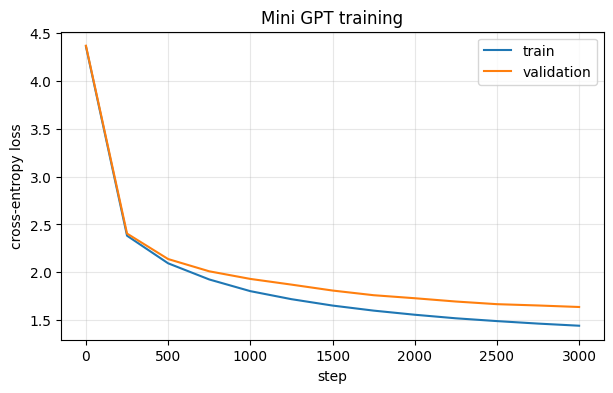

Final train loss: 1.4420
Final validation loss: 1.6375


In [ ]:
plt.figure(figsize=(7, 4))
plt.plot(history['step'], history['train'], label='train')
plt.plot(history['step'], history['val'], label='validation')
plt.xlabel('step')
plt.ylabel('cross-entropy loss')
plt.title('Mini GPT training')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print(f"Final train loss: {history['train'][-1]:.4f}")
print(f"Final validation loss: {history['val'][-1]:.4f}")

## 7. Generate text

In [ ]:
model.eval()
context = torch.zeros((1, 1), dtype=torch.long, device=device)   # start from a single token
out = model.generate(context, max_new_tokens=600, temperature=0.8, top_k=40)
print(decode(out[0].tolist()))



GLOUCESTER:
Romeo, holy he banks appares their of the valoucest the
with a missed of the of as joises;
Inder a many to tame to that prison, and the meous of that tongue cousin.

MENENIUS:
No, my both uself, sir.

BRUTUS:
We will not say, Partiant, then, so so not of the curt
stands of a cause with mouth art but them partitor,
Titled sleeps this no morrow.
3 HENRY VI:
Anting not spiring, for think the words? The beast I land,
Hath hand but that I'll be in the breath to the Towas of Hertings.

KING HENRY VI:
What you shall I may not us grave to your before,
Make not a man true some for must him


In [ ]:
# Generate from your own prompt
prompt = 'ROMEO:'
ctx = torch.tensor([encode(prompt)], dtype=torch.long, device=device)
out = model.generate(ctx, max_new_tokens=400, temperature=0.8, top_k=40)
print(decode(out[0].tolist()))

ROMEO:
And what is my far; the wise blood made thee,
And some to prince the too-seem arm us bow,
This hearts revous so bood fair so to him;
Show come the countent of the firms by goes and thou knock.

Second Murderer:
While hent the wilt tilt of this prison,
To see sit and rest, that is be sleep me in here,
To you with hear him. My lord, what shall you are thee beheed,
And time and not the people of us 


## 8. Save the model

In [ ]:
torch.save(model.state_dict(), 'mini_gpt.pt')
print('Saved mini_gpt.pt')

Saved mini_gpt.pt
